# Modelos Lineales y Correlación

### Importar librerías

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

### Carga de datos

In [12]:
#cargamos el conjunto de datos ya limpio
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")

### Correlación entre las variables con la satisfacción con la vida

In [3]:
#asignamos a una variable todas las preguntas con las que puede haber una correlacion
preguntas = (['cs_EDA', 'cs_ING', 'viv_P1', 'cb_P2']
              + [f'cb_P3_{i}' for i in range(1, 12)]
              + [f'cb_P4_{i}' for i in range(1, 11)]
              + [f'cb_P5_{i}' for i in range(1, 13)])

#calculamos la correlación entre cada una de las preguntas y la satisfaccion con la vida, quitando la pregunta misma de la satisfaccion con la vida
correlaciones = df_biare[preguntas + ['cb_P1']].corr()['cb_P1'].drop('cb_P1').sort_values(ascending=False)

print(correlaciones.round(3))

cb_P2       0.618
cb_P3_1     0.598
cb_P5_1     0.478
cb_P3_2     0.461
cb_P3_5     0.426
cb_P5_2     0.416
cb_P3_6     0.414
cb_P5_3     0.413
cb_P5_5     0.406
cb_P3_10    0.393
cb_P5_4     0.391
cb_P3_4     0.365
cb_P5_8     0.331
cb_P3_8     0.331
cb_P3_3     0.330
cb_P4_5     0.326
cb_P3_7     0.322
cb_P5_9     0.313
cb_P4_4     0.295
cb_P4_3     0.292
cb_P4_2     0.281
cb_P5_6     0.274
cb_P4_1     0.272
cb_P5_10    0.225
cb_P5_11    0.204
cb_P5_12    0.193
cb_P5_7     0.185
cb_P3_9     0.107
cs_ING      0.088
viv_P1     -0.005
cs_EDA     -0.093
cb_P3_11   -0.126
cb_P4_6    -0.201
cb_P4_9    -0.244
cb_P4_8    -0.253
cb_P4_7    -0.254
cb_P4_10   -0.290
Name: cb_P1, dtype: float64


Aunque cb_P2 es la que mayor correlacion mostro, no la tomamos como la primera a analizar, ya que esta pregunta hace referencia a la satisfacción con la vida que se tenía hace un año, por lo que analizaremos primero la siguiente, la cual es cb_P3_1 que es me siento bien conmigo mismo.

### Modelos lineales

#### Modelo lineal sobre me siento bien conmigo mismo

##### carga de datos

In [19]:
#preparamos los datos para realizar nuestro modelo, quitamos nuestras pregunta a analizar y nuestra pregunta objetivo que es la satisfaccion con la vida
datos = df_biare[['cb_P3_1', 'cb_P1']].dropna()

#se guarda en x nuestra pregunta a analizar y en y nuestra pregunta objetivo que es la satisfaccion con la vida
X = datos[['cb_P3_1']]   #hay que usar doble corchete porque en statsmodels lee tablas, no columnas
X_sm = sm.add_constant(X)  #agregamos una constante para el modelo de statsmodels
y = datos['cb_P1']

##### creamos el modelo y lo ajustamos para tener r cuadrada

In [20]:
#creamos el modelo de regresion lineal con statsmodels y lo entrenamos
modelo_sm = sm.OLS(y, X_sm).fit()
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  cb_P1   R-squared:                       0.357
Model:                            OLS   Adj. R-squared:                  0.357
Method:                 Least Squares   F-statistic:                     4454.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        13:48:32   Log-Likelihood:                -13582.
No. Observations:                8019   AIC:                         2.717e+04
Df Residuals:                    8017   BIC:                         2.718e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.6570      0.087     30.559      0.0

con el resultado del coef podemos ver que por cada punto que se tiene en la pregunta de me siento bien conmigo mismo, la satisfacción con la vida sube 0.65 puntos.

con el resultado de coef de const se obtiene lo que el modelo predice cuando alguien contesta 0, debido a que muy pocas personas contestaron 0, es complicado para el modelo predecirlo, pero obtiene 2.65 de satisfaccion con la vida.

con el resultado de r cuadrada que es igual a 0.357, se obtiene que aproximadamente el 36% de las diferencias en la satisfaccion con la vida vienen de la pregunta me siento bien conmigo mismo

Los residuos no son normales, por lo que se tiene que hay mas erroes en los extremos.

##### Grafica del modelo

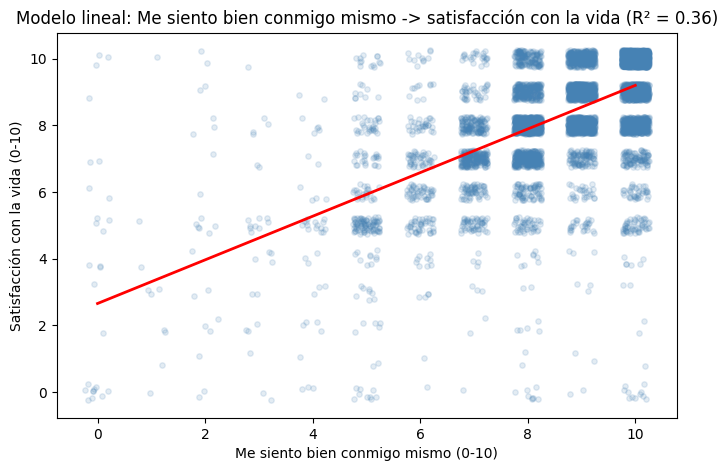

In [24]:
rng = np.random.default_rng(42)
x_jit = X['cb_P3_1'] + rng.uniform(-0.25, 0.25, len(X))
y_jit = y + rng.uniform(-0.25, 0.25, len(y))

x_linea = pd.DataFrame({'cb_P3_1': np.linspace(0, 10, 100)})
y_linea = modelo_sm.predict(sm.add_constant(x_linea))

plt.figure(figsize=(8, 5))
plt.scatter(x_jit, y_jit, alpha=0.15, color='steelblue', s=15)
plt.plot(x_linea['cb_P3_1'], y_linea, color='red', linewidth=2)
plt.title(f'Modelo lineal: Me siento bien conmigo mismo -> satisfacción con la vida (R² = {modelo_sm.rsquared:.2f})')
plt.xlabel('Me siento bien conmigo mismo (0-10)')
plt.ylabel('Satisfacción con la vida (0-10)')
plt.show()

#### Modelo lineal sobre satisfaccion con el nivel de vida

##### carga de datos

In [26]:
#preparamos los datos para realizar nuestro modelo, quitamos nuestras pregunta a analizar y nuestra pregunta objetivo que es la satisfaccion con la vida
datos_p5_1 = df_biare[['cb_P5_1', 'cb_P1']].dropna()

#se guarda en x nuestra pregunta a analizar y en y nuestra pregunta objetivo que es la satisfaccion con la vida
X_p5_1 = datos_p5_1[['cb_P5_1']] #hay que usar doble corchete porque en statsmodels lee tablas, no columnas
X_sm_p5_1 = sm.add_constant(X_p5_1) #agregamos una constante para el modelo de statsmodels
y_p5_1 = datos_p5_1['cb_P1']


##### creamos el modelo y lo ajustamos para tener r cuadrada

In [28]:
#creamos el modelo de regresion lineal con statsmodels y lo entrenamos
modelo_sm_p5_1 = sm.OLS(y_p5_1, X_sm_p5_1).fit()
print(modelo_sm_p5_1.summary())

                            OLS Regression Results                            
Dep. Variable:                  cb_P1   R-squared:                       0.228
Model:                            OLS   Adj. R-squared:                  0.228
Method:                 Least Squares   F-statistic:                     2368.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:52:13   Log-Likelihood:                -14316.
No. Observations:                8019   AIC:                         2.864e+04
Df Residuals:                    8017   BIC:                         2.865e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.3600      0.084     51.851      0.0

con el resultado del coef podemos ver que por cada punto que se tiene en la pregunta nivel de vida, la satisfacción con la vida sube 0.48 puntos.

con el resultado de coef de const se obtiene lo que el modelo predice cuando alguien contesta 0, debido a que muy pocas personas contestaron 0, es complicado para el modelo predecirlo, pero obtiene 4.36 de satisfaccion con la vida.

con el resultado de r cuadrada que es igual a 0.228, se obtiene que aproximadamente el 23% de las diferencias en la satisfaccion con la vida vienen de la pregunta nivel de vida

Los residuos no son normales, por lo que se tiene que hay mas erroes en los extremos.

##### Grafica del modelo

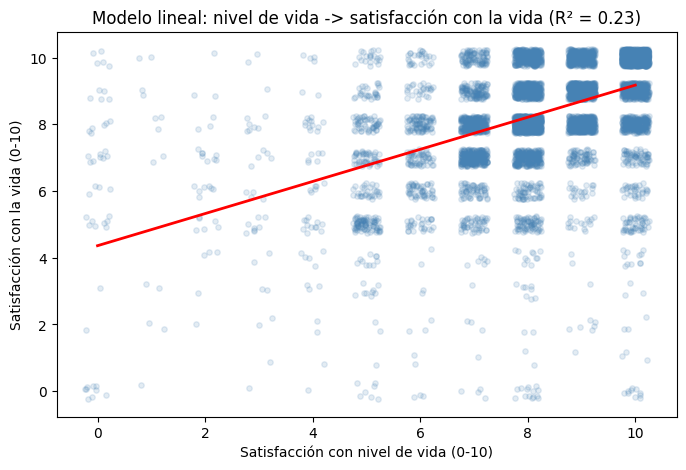

In [31]:
rng = np.random.default_rng(42)
x_jit = X_p5_1['cb_P5_1'] + rng.uniform(-0.25, 0.25, len(X_p5_1))
y_jit = y_p5_1 + rng.uniform(-0.25, 0.25, len(y_p5_1))

x_linea = pd.DataFrame({'cb_P5_1': np.linspace(0, 10, 100)})
y_linea = modelo_sm_p5_1.predict(sm.add_constant(x_linea))

plt.figure(figsize=(8, 5))
plt.scatter(x_jit, y_jit, alpha=0.15, color='steelblue', s=15)
plt.plot(x_linea['cb_P5_1'], y_linea, color='red', linewidth=2)
plt.title(f'Modelo lineal: nivel de vida -> satisfacción con la vida (R² = {modelo_sm_p5_1.rsquared:.2f})')
plt.xlabel('Satisfacción con nivel de vida (0-10)')
plt.ylabel('Satisfacción con la vida (0-10)')
plt.show()

#### Modelo lineal sobre la pregunta ¿te sentiste triste ayer?

##### carga de datos

In [33]:
#preparamos los datos para realizar nuestro modelo, quitamos nuestras pregunta a analizar y nuestra pregunta objetivo que es la satisfaccion con la vida
datos_p4_10 = df_biare[['cb_P4_10', 'cb_P1']].dropna()

#se guarda en x nuestra pregunta a analizar y en y nuestra pregunta objetivo que es la satisfaccion con la vida
X_p4_10 = datos_p4_10[['cb_P4_10']] #hay que usar doble corchete porque en statsmodels lee tablas, no columnas
X_sm_p4_10 = sm.add_constant(X_p4_10)
y_p4_10 = datos_p4_10['cb_P1']


##### creamos el modelo y lo ajustamos para tener r cuadrada

In [34]:
#creamos el modelo de regresion lineal con statsmodels y lo entrenamos
modelo_sm_p4_10 = sm.OLS(y_p4_10, X_sm_p4_10).fit()
print(modelo_sm_p4_10.summary())

                            OLS Regression Results                            
Dep. Variable:                  cb_P1   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                  0.084
Method:                 Least Squares   F-statistic:                     734.1
Date:                Sun, 11 Oct 2026   Prob (F-statistic):          9.31e-155
Time:                        18:11:43   Log-Likelihood:                -15002.
No. Observations:                8019   AIC:                         3.001e+04
Df Residuals:                    8017   BIC:                         3.002e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.6640      0.021    422.403      0.0

con el resultado del coef podemos ver que por cada punto que se tiene en la pregunta ¿te sentiste triste ayer?, la satisfacción con la vida disminuye 0.25 puntos.

con el resultado de coef de const se obtiene lo que el modelo predice cuando alguien contesta 0, debido a que muy pocas personas contestaron 0, es complicado para el modelo predecirlo, pero obtiene 8.66 de satisfaccion con la vida, esto tiene sentido, ya que es una pregunta negativa.

con el resultado de r cuadrada que es igual a 0.084, se obtiene que aproximadamente el 8% de las diferencias en la satisfaccion con la vida vienen de la pregunta ¿te sentiste triste ayer?

Los residuos no son normales, por lo que se tiene que hay mas erroes en los extremos.

##### Grafica del modelo

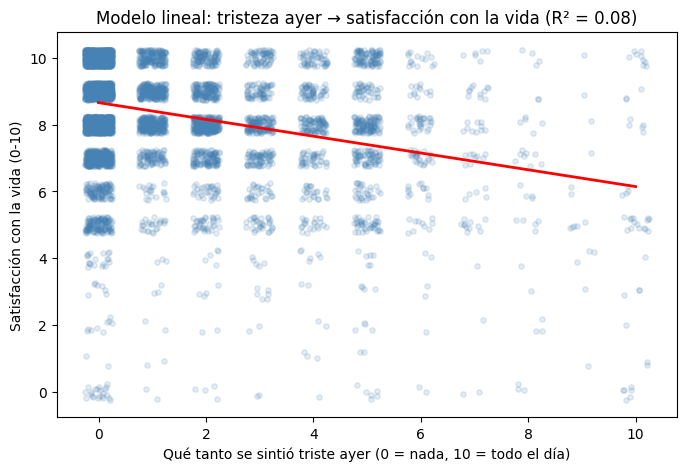

In [36]:
rng = np.random.default_rng(42)
x_jit = X_p4_10['cb_P4_10'] + rng.uniform(-0.25, 0.25, len(X_p4_10))
y_jit = y_p4_10 + rng.uniform(-0.25, 0.25, len(y_p4_10))

x_linea = pd.DataFrame({'cb_P4_10': np.linspace(0, 10, 100)})
y_linea = modelo_sm_p4_10.predict(sm.add_constant(x_linea))

plt.figure(figsize=(8, 5))
plt.scatter(x_jit, y_jit, alpha=0.15, color='steelblue', s=15)
plt.plot(x_linea['cb_P4_10'], y_linea, color='red', linewidth=2)
plt.title(f'Modelo lineal: tristeza ayer → satisfacción con la vida (R² = {modelo_sm_p4_10.rsquared:.2f})')
plt.xlabel('Qué tanto se sintió triste ayer (0 = nada, 10 = todo el día)')
plt.ylabel('Satisfacción con la vida (0-10)')
plt.show()

#### Modelo lineal sobre la pregunta satisfaccion con la seguridad ciudadana

##### carga de datos

In [40]:
#preparamos los datos para realizar nuestro modelo, quitamos nuestras pregunta a analizar y nuestra pregunta objetivo que es la satisfaccion con la vida
datos_p5_7 = df_biare[['cb_P5_7', 'cb_P1']].dropna()

#se guarda en x nuestra pregunta a analizar y en y nuestra pregunta objetivo que es la satisfaccion con la vida
X_p5_7 = datos_p5_7[['cb_P5_7']] #hay que usar doble corchete porque en statsmodels lee tablas, no columnas
X_sm_p5_7 = sm.add_constant(X_p5_7)
y_p5_7 = datos_p5_7['cb_P1']


##### creamos el modelo y lo ajustamos para tener r cuadrada

In [41]:
#creamos el modelo de regresion lineal con statsmodels y lo entrenamos
modelo_sm_p5_7 = sm.OLS(y_p5_7, X_sm_p5_7).fit()
print(modelo_sm_p5_7.summary())

                            OLS Regression Results                            
Dep. Variable:                  cb_P1   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     284.5
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           9.26e-63
Time:                        18:53:15   Log-Likelihood:                -15214.
No. Observations:                8019   AIC:                         3.043e+04
Df Residuals:                    8017   BIC:                         3.045e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8057      0.038    203.632      0.0

con el resultado del coef podemos ver que por cada punto que se tiene en la pregunta seguridad ciudadana, la satisfacción con la vida aumenta 0.10 puntos.

con el resultado de coef de const se obtiene lo que el modelo predice cuando alguien contesta 0, obtiene 7.8 de satisfaccion con la vida.

con el resultado de r cuadrada que es igual a 0.034, se obtiene que aproximadamente el 3% de las diferencias en la satisfaccion con la vida vienen de la pregunta seguridad ciudadana

Los residuos no son normales, por lo que se tiene que hay mas erroes en los extremos.

##### Grafica del modelo

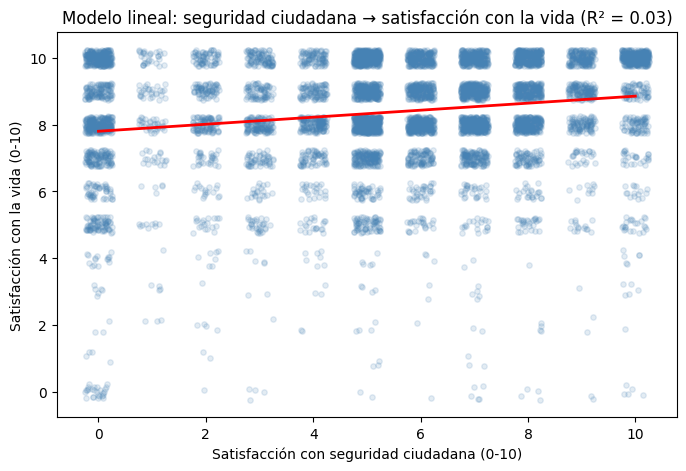

In [46]:
rng = np.random.default_rng(42)
x_jit = X_p5_7['cb_P5_7'] + rng.uniform(-0.25, 0.25, len(X_p5_7))
y_jit = y_p5_7 + rng.uniform(-0.25, 0.25, len(y_p5_7))

x_linea = pd.DataFrame({'cb_P5_7': np.linspace(0, 10, 100)})
y_linea = modelo_sm_p5_7.predict(sm.add_constant(x_linea))

plt.figure(figsize=(8, 5))
plt.scatter(x_jit, y_jit, alpha=0.15, color='steelblue', s=15)
plt.plot(x_linea['cb_P5_7'], y_linea, color='red', linewidth=2)
plt.title(f'Modelo lineal: seguridad ciudadana → satisfacción con la vida (R² = {modelo_sm_p5_7.rsquared:.2f})')
plt.xlabel('Satisfacción con seguridad ciudadana (0-10)')
plt.ylabel('Satisfacción con la vida (0-10)')
plt.show()

#### Modelo lineal sobre la edad

##### carga de datos

In [43]:
#preparamos los datos para realizar nuestro modelo, quitamos nuestras pregunta a analizar y nuestra pregunta objetivo que es la satisfaccion con la vida
datos_eda = df_biare[['cs_EDA', 'cb_P1']].dropna()

#se guarda en x nuestra pregunta a analizar y en y nuestra pregunta objetivo que es la satisfaccion con la vida
X_eda = datos_eda[['cs_EDA']] #hay que usar doble corchete porque en statsmodels lee tablas, no columnas
X_sm_eda = sm.add_constant(X_eda)
y_eda = datos_eda['cb_P1']

##### creamos el modelo y lo ajustamos para tener r cuadrada

In [44]:
#creamos el modelo de regresion lineal con statsmodels y lo entrenamos
modelo_sm_eda = sm.OLS(y_eda, X_sm_eda).fit()
print(modelo_sm_eda.summary())

                            OLS Regression Results                            
Dep. Variable:                  cb_P1   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     69.40
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           9.36e-17
Time:                        19:48:19   Log-Likelihood:                -15319.
No. Observations:                8019   AIC:                         3.064e+04
Df Residuals:                    8017   BIC:                         3.066e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          8.7927      0.053    165.267      0.0

con el resultado del coef podemos ver que por cada punto que se tiene en la pregunta satosfaccion ciudadana, la satisfacción con la vida disminuye 0.009 puntos.

con el resultado de r cuadrada que es igual a 0.009, se obtiene que aproximadamente el 0.9% de las diferencias en la satisfaccion con la vida vienen de la edad.

Los residuos no son normales, por lo que se tiene que hay mas erroes en los extremos.

##### Grafica del modelo

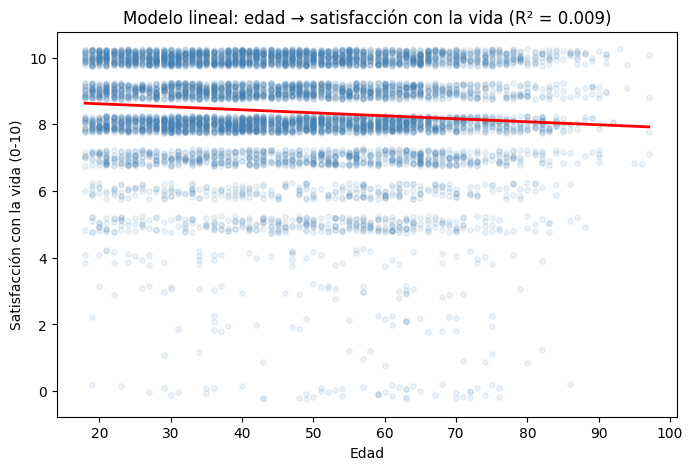

In [48]:
rng = np.random.default_rng(42)
y_jit = y_eda + rng.uniform(-0.25, 0.25, len(y_eda))

x_linea = pd.DataFrame({'cs_EDA': np.linspace(X_eda['cs_EDA'].min(), X_eda['cs_EDA'].max(), 100)})
y_linea = modelo_sm_eda.predict(sm.add_constant(x_linea))

plt.figure(figsize=(8, 5))
plt.scatter(X_eda['cs_EDA'], y_jit, alpha=0.1, color='steelblue', s=15)
plt.plot(x_linea['cs_EDA'], y_linea, color='red', linewidth=2)
plt.title(f'Modelo lineal: edad → satisfacción con la vida (R² = {modelo_sm_eda.rsquared:.3f})')
plt.xlabel('Edad')
plt.ylabel('Satisfacción con la vida (0-10)')
plt.show()